# Module 1 Assignment

In [19]:
import warnings
import itertools, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (13, 4)
DATA = 'data/'
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')

In [20]:
cal = pd.read_csv(DATA + 'calendar.csv', parse_dates=['date'])
sales = pd.read_csv(DATA + 'sales_train_evaluation.csv')

day_cols = [c for c in sales.columns if c.startswith('d_')]
total = sales[day_cols].sum()

total.index = cal.set_index('d').loc[total.index, 'date'].values
y = total.astype(float).rename('sales')
y.index = pd.DatetimeIndex(y.index, freq='D')
del sales

print('Days:', len(y), '|', y.index.min().date(), 'to', y.index.max().date())
y.describe().round(0)

Days: 1941 | 2011-01-29 to 2016-05-22


count     1941.0
mean     34481.0
std       7426.0
min         11.0
25%      29713.0
50%      33830.0
75%      39008.0
max      59921.0
Name: sales, dtype: float64

### Clean closed days
A day is treated as closed (store holiday) when sales fall below 30% of the local monthly median. Those days are replaced by interpolation.

Closed days found: [datetime.date(2011, 12, 25), datetime.date(2012, 12, 25), datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25)]


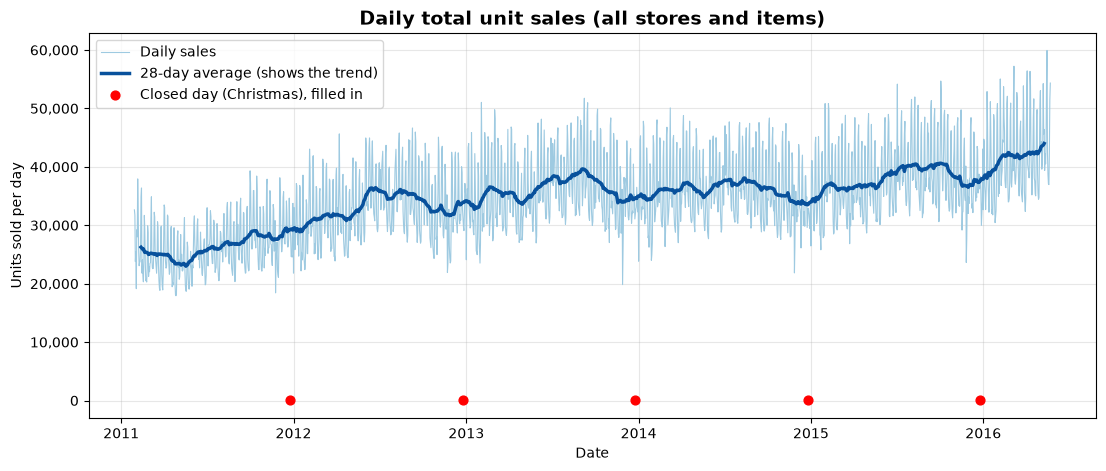

In [21]:
closed = y < 0.3 * y.rolling(31, center=True, min_periods=1).median()
print('Closed days found:', list(y[closed].index.date))
y_raw = y.copy()
y = y.mask(closed).interpolate()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y.index, y.values, color='#9ecae1', lw=0.8, label='Daily sales')
ax.plot(y.index, y.rolling(28, center=True).mean(), color='#08519c', lw=2.5, label='28-day average (shows the trend)')
ax.scatter(y_raw.index[closed], y_raw[closed], color='red', zorder=3, s=40, label='Closed day (Christmas), filled in')
ax.yaxis.set_major_formatter(thousands)
ax.set_title('Daily total unit sales (all stores and items)', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.grid(alpha=0.3)
ax.legend(loc='upper left')
plt.show()

**How to read this:** the light blue line is daily sales and the dark line is the 28-day average, which shows sales rising over time. The red dots are Christmas Days, when the stores were closed; those days were filled in so they do not distort the analysis.

---
## Assignment 1: Decompose the sales dataset into trend, seasonality and residual

1) All values positive: True (min = 17929)
2) Corr(level, swing in units) = 0.82  (high -> multiplicative)
   Variation of swing across blocks: units CV = 0.16, relative CV = 0.10  (lower = more constant)
3) Residual std (relative to level): additive = 0.0656, multiplicative = 0.0624
   Corr(|residual|, level): additive = -0.09, multiplicative = -0.05  (near 0 = good)


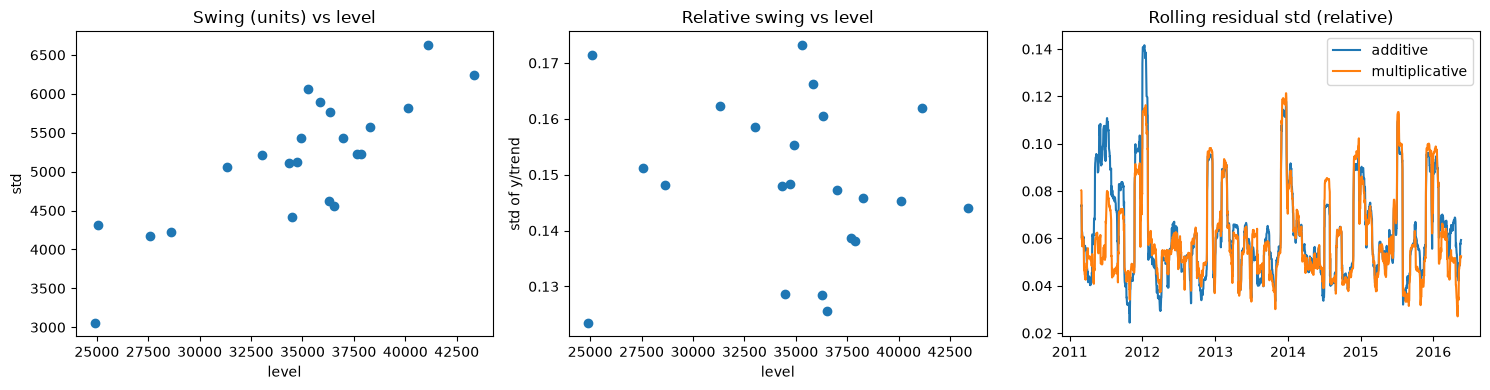


Votes for MULTIPLICATIVE: 3 of 3 -> use MULTIPLICATIVE


In [4]:
print('1) All values positive:', bool(y.min() > 0), f'(min = {y.min():.0f})')

trend7 = y.rolling(7, center=True).mean()
abs_swing = (y - trend7).dropna()
rel_swing = (y / trend7).dropna()
blocks = pd.DataFrame({'level': trend7, 'abs_swing': abs_swing, 'rel_swing': rel_swing}).dropna()
g = blocks.groupby(np.arange(len(blocks)) // 90)
blk = pd.DataFrame({'level': g['level'].mean(),
                    'abs_std': g['abs_swing'].std(),
                    'rel_std': g['rel_swing'].std()})
r_abs = blk['level'].corr(blk['abs_std'])
cv_abs = blk['abs_std'].std() / blk['abs_std'].mean()
cv_rel = blk['rel_std'].std() / blk['rel_std'].mean()
print(f"2) Corr(level, swing in units) = {r_abs:.2f}  (high -> multiplicative)")
print(f"   Variation of swing across blocks: units CV = {cv_abs:.2f}, relative CV = {cv_rel:.2f}  (lower = more constant)")

dec_add = seasonal_decompose(y, model='additive', period=7)
dec_mul = seasonal_decompose(y, model='multiplicative', period=7)
res_add = dec_add.resid.dropna() / dec_add.trend.dropna()
res_mul = dec_mul.resid.dropna() - 1
print(f"3) Residual std (relative to level): additive = {res_add.std():.4f}, multiplicative = {res_mul.std():.4f}")
print(f"   Corr(|residual|, level): additive = {res_add.abs().corr(dec_add.trend.dropna()):.2f}, "
      f"multiplicative = {res_mul.abs().corr(dec_mul.trend.dropna()):.2f}  (near 0 = good)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(blk['level'], blk['abs_std'])
ax[0].set(title='Swing (units) vs level', xlabel='level', ylabel='std')
ax[1].scatter(blk['level'], blk['rel_std'])
ax[1].set(title='Relative swing vs level', xlabel='level', ylabel='std of y/trend')
ax[2].plot(res_add.rolling(28).std(), label='additive')
ax[2].plot(res_mul.rolling(28).std(), label='multiplicative')
ax[2].set(title='Rolling residual std (relative)')
ax[2].legend()
plt.tight_layout()
plt.show()

score = int(r_abs > 0.5) + int(cv_rel < cv_abs) + int(res_mul.std() < res_add.std())
print()
print('Votes for MULTIPLICATIVE:', score, 'of 3 ->',
      'use MULTIPLICATIVE' if score >= 2 else 'use ADDITIVE')

**Result:** all three checks favour a multiplicative model, because the weekly swing grows with the sales level.

### 1.2 Multiplicative decomposition (period = 7)

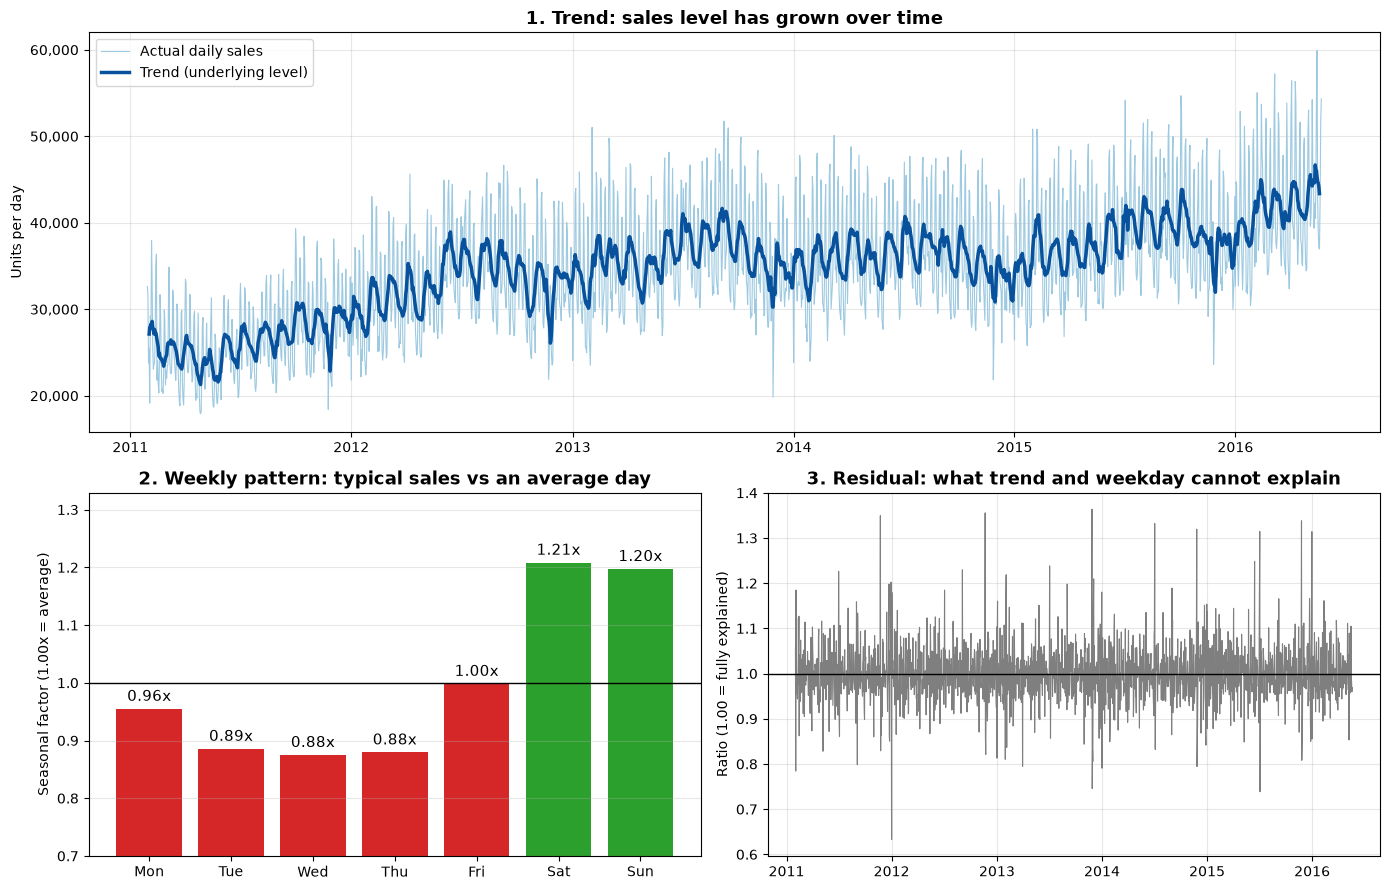

In [5]:
dec_mul = seasonal_decompose(y, model='multiplicative', period=7)
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_factor = dec_mul.seasonal.groupby(dec_mul.seasonal.index.dayofweek).mean()

fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(y.index, y.values, color='#9ecae1', lw=0.8, label='Actual daily sales')
ax1.plot(dec_mul.trend.index, dec_mul.trend.values, color='#08519c', lw=2.5, label='Trend (underlying level)')
ax1.yaxis.set_major_formatter(thousands)
ax1.set_title('1. Trend: sales level has grown over time', fontsize=13, fontweight='bold')
ax1.set_ylabel('Units per day')
ax1.legend(loc='upper left')
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[1, 0])
bars = ax2.bar(days, weekday_factor.values, color=['#2ca02c' if v > 1 else '#d62728' for v in weekday_factor.values])
ax2.bar_label(bars, labels=[f'{v:.2f}x' for v in weekday_factor.values], padding=3, fontsize=11)
ax2.axhline(1, color='black', lw=1)
ax2.set_ylim(0.7, weekday_factor.max() * 1.1)
ax2.set_title('2. Weekly pattern: typical sales vs an average day', fontsize=13, fontweight='bold')
ax2.set_ylabel('Seasonal factor (1.00x = average)')
ax2.grid(axis='y', alpha=0.3)

ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(dec_mul.resid.index, dec_mul.resid.values, color='#7f7f7f', lw=0.8)
ax3.axhline(1, color='black', lw=1)
ax3.set_title('3. Residual: what trend and weekday cannot explain', fontsize=13, fontweight='bold')
ax3.set_ylabel('Ratio (1.00 = fully explained)')
ax3.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**How to read this:** the dark line shows the long-term level of sales, which rises over the five years. The bars show that weekend days sell more than the average day and mid-week days sell less. The residual stays close to 1.00, so trend and weekday explain most of the movement.

### 1.3 STL decomposition 

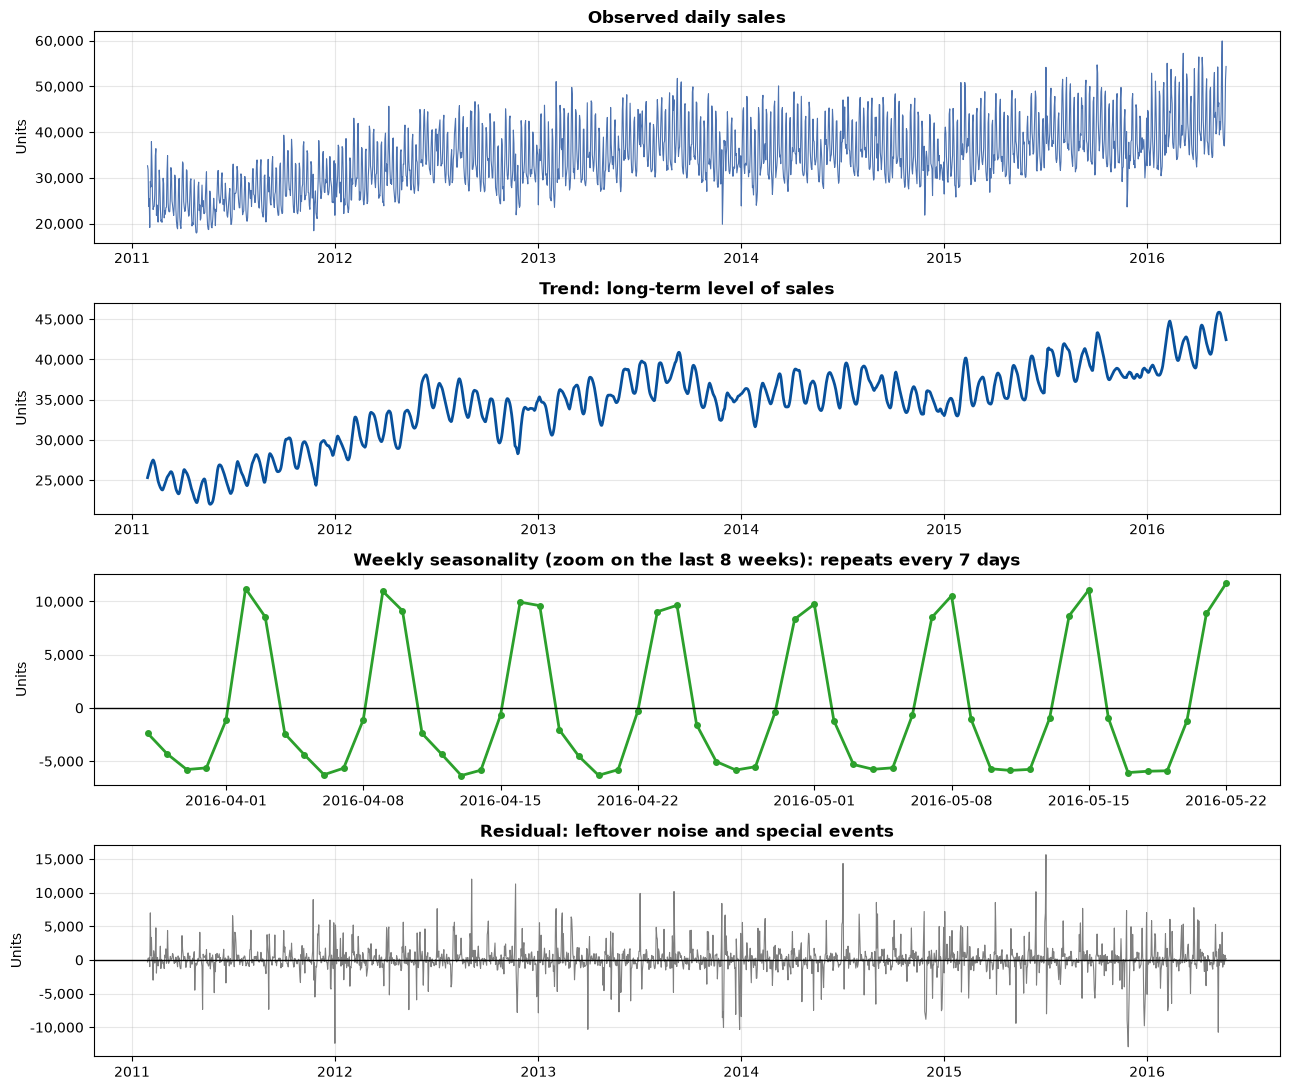

Trend strength             : 0.83  (closer to 1 = stronger)
Weekly seasonality strength: 0.82  (closer to 1 = stronger)


In [6]:
stl = STL(y, period=7, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 11))
axes[0].plot(y.index, y.values, color='#4c72b0', lw=0.8)
axes[0].set_title('Observed daily sales', fontsize=12, fontweight='bold')
axes[1].plot(stl.trend.index, stl.trend.values, color='#08519c', lw=2)
axes[1].set_title('Trend: long-term level of sales', fontsize=12, fontweight='bold')
recent = stl.seasonal.iloc[-56:]
axes[2].plot(recent.index, recent.values, color='#2ca02c', lw=2, marker='o', ms=4)
axes[2].axhline(0, color='black', lw=1)
axes[2].set_title('Weekly seasonality (zoom on the last 8 weeks): repeats every 7 days', fontsize=12, fontweight='bold')
axes[3].plot(stl.resid.index, stl.resid.values, color='#7f7f7f', lw=0.8)
axes[3].axhline(0, color='black', lw=1)
axes[3].set_title('Residual: leftover noise and special events', fontsize=12, fontweight='bold')
for ax in axes:
    ax.yaxis.set_major_formatter(thousands)
    ax.set_ylabel('Units')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

trend_strength = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
season_strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f'Trend strength             : {trend_strength:.2f}  (closer to 1 = stronger)')
print(f'Weekly seasonality strength: {season_strength:.2f}  (closer to 1 = stronger)')

**How to read this:** STL splits the series into trend, a weekly pattern that repeats every 7 days, and a small leftover. The two strength scores below show how much of the series each part explains.

**Result:** the series has a strong upward trend (strength 0.83) and a strong weekly pattern (strength 0.82).

## Assignment 2: Test stationarity with ADF and KPSS and transform the data accordingly

### 2.1 Stationarity test function
* **ADF:** null hypothesis is a unit root (non-stationary). A p-value below 0.05 suggests the series is stationary.
* **KPSS:** null hypothesis is stationarity. A p-value of 0.05 or above suggests the series is stationary.
* Both tests agreeing gives a reliable verdict.

In [7]:
def stationarity_report(s, name):
    s = s.dropna()
    adf = adfuller(s, autolag='AIC')
    kp = kpss(s, regression='c', nlags='auto')
    adf_says_stationary = adf[1] < 0.05
    kpss_says_stationary = kp[1] >= 0.05
    verdict = {(True, True): 'STATIONARY',
               (False, False): 'NON-STATIONARY',
               (True, False): 'difference-stationary',
               (False, True): 'trend-stationary'}[(adf_says_stationary, kpss_says_stationary)]
    return {'series': name, 'ADF p-value': adf[1], 'KPSS p-value': kp[1], 'verdict': verdict}

### 2.2 Apply transformations and re-test

In [8]:
ylog = np.log(y)
log_d1 = ylog.diff().dropna()
log_d1_d7 = ylog.diff().diff(7).dropna()

rows = [stationarity_report(y, 'Original'),
        stationarity_report(ylog, 'log'),
        stationarity_report(y.diff(), 'diff(1)'),
        stationarity_report(y.diff(7), 'seasonal diff(7)'),
        stationarity_report(log_d1, 'log + diff(1)'),
        stationarity_report(ylog.diff(7), 'log + seasonal diff(7)'),
        stationarity_report(log_d1_d7, 'log + diff(1) + seasonal diff(7)')]
res = pd.DataFrame(rows).set_index('series')
res.style.format({'ADF p-value': '{:.4f}', 'KPSS p-value': '{:.3f}'})

,ADF p-value,KPSS p-value,verdict
series,,,
Original,0.6533,0.010,NON-STATIONARY
log,0.5508,0.010,NON-STATIONARY
diff(1),0.0000,0.100,STATIONARY
seasonal diff(7),0.0000,0.100,STATIONARY
log + diff(1),0.0000,0.100,STATIONARY
log + seasonal diff(7),0.0000,0.100,STATIONARY
log + diff(1) + seasonal diff(7),0.0000,0.100,STATIONARY


**Result:** the original and log series are non-stationary. A first difference removes the trend and makes the series stationary on both tests. The log transform stabilises the variance, so log + diff(1) + seasonal diff(7) is used for modelling.

### 2.3 Visual check

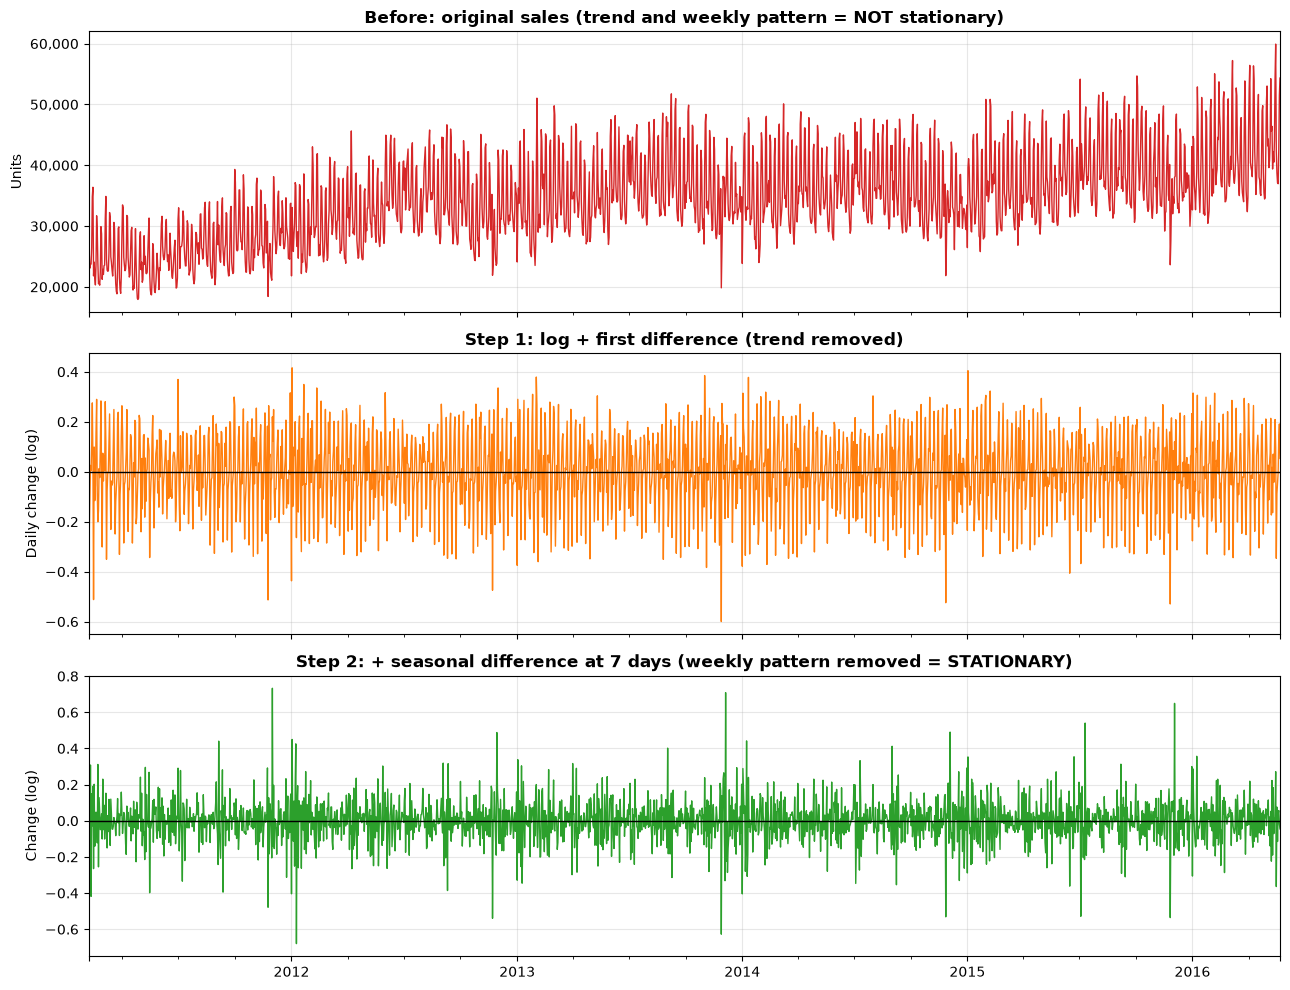

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
y.plot(ax=ax[0], color='#d62728', lw=1)
ax[0].set_title('Before: original sales (trend and weekly pattern = NOT stationary)', fontsize=12, fontweight='bold')
ax[0].set_ylabel('Units')
ax[0].yaxis.set_major_formatter(thousands)
log_d1.plot(ax=ax[1], color='#ff7f0e', lw=1)
ax[1].set_title('Step 1: log + first difference (trend removed)', fontsize=12, fontweight='bold')
ax[1].set_ylabel('Daily change (log)')
log_d1_d7.plot(ax=ax[2], color='#2ca02c', lw=1)
ax[2].set_title('Step 2: + seasonal difference at 7 days (weekly pattern removed = STATIONARY)', fontsize=12, fontweight='bold')
ax[2].set_ylabel('Change (log)')
for a in ax:
    a.grid(alpha=0.3)
ax[2].axhline(0, color='black', lw=1)
ax[1].axhline(0, color='black', lw=1)
plt.tight_layout()
plt.show()

**How to read this:** the red series drifts upwards, so its statistics change over time. After the two differencing steps the green series moves around zero with a constant spread, which is what a stationary series looks like.

### 2.4 ACF and PACF
These plots show how strongly each day is related to earlier days and help choose the ARIMA orders (p, q) used in Assignment 3.

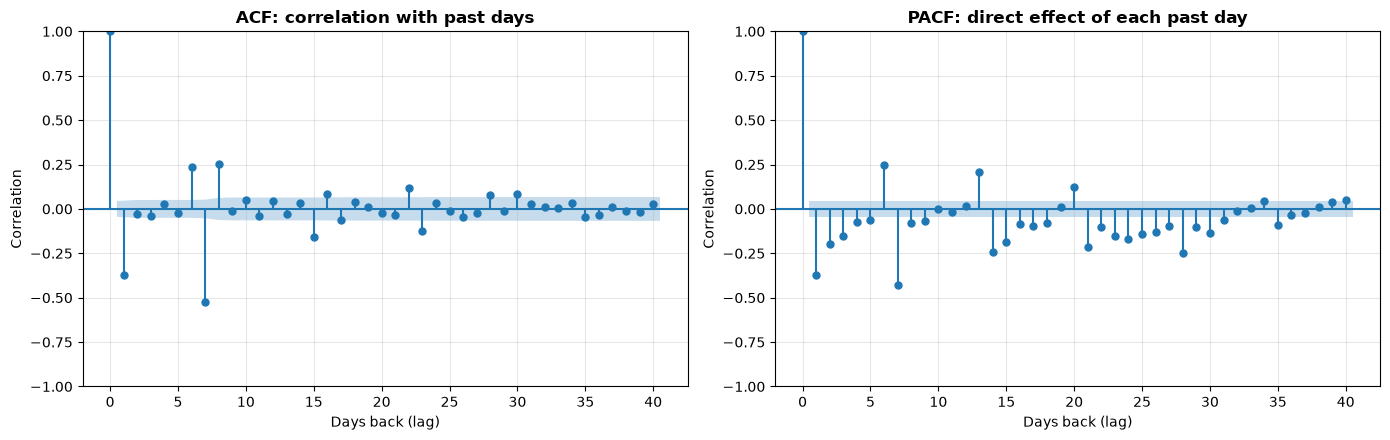

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(log_d1_d7, lags=40, ax=ax[0], title='ACF: correlation with past days')
plot_pacf(log_d1_d7, lags=40, ax=ax[1], title='PACF: direct effect of each past day')
for a in ax:
    a.set_xlabel('Days back (lag)')
    a.set_ylabel('Correlation')
    a.title.set_fontweight('bold')
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**How to read this:** bars outside the blue band are statistically significant. Spikes at lags 1 and 7 confirm short-term and weekly dependence, which guides the ARIMA settings.

## Assignment 3: Fit ARIMA and Prophet, compare predictions with MAE, RMSE and MAPE

The last 28 days (the standard M5 horizon) are held out as a test set. Both models are trained on the earlier data, forecast those 28 days, and are scored against the actual sales.

* **MAE:** average miss in units per day.
* **RMSE:** like MAE but penalises large misses more.
* **MAPE:** average miss as a percentage of actual sales.


### 3.1 Train/test split and metric function

In [11]:
H = 28
train, test = y.iloc[:-H], y.iloc[-H:]
print('Train ends:', train.index.max().date(), '| Test:', test.index.min().date(), 'to', test.index.max().date())

def metrics(actual, pred, name):
    return {'model': name,
            'MAE': mean_absolute_error(actual, pred),
            'RMSE': np.sqrt(mean_squared_error(actual, pred)),
            'MAPE (%)': np.mean(np.abs((actual - pred) / actual)) * 100}

Train ends: 2016-04-24 | Test: 2016-04-25 to 2016-05-22


### 3.2 ARIMA
The differencing order is fixed at `d = 1` (from Assignment 2). The orders `p` and `q` are chosen by the lowest AIC over a small grid. The model is fitted on log sales and the forecast is converted back with `exp`.

In [12]:
ltrain = np.log(train).iloc[-1100:]
best, t0 = None, time.time()
for p, q in itertools.product(range(0, 8), range(0, 4)):
    try:
        fit = ARIMA(ltrain, order=(p, 1, q)).fit()
        if best is None or fit.aic < best[0]:
            best = (fit.aic, (p, 1, q))
    except Exception:
        pass
print(f'Best settings -> order={best[1]}  (AIC={best[0]:.0f}, {time.time()-t0:.0f}s)')

Best settings -> order=(5, 1, 3)  (AIC=-2186, 18s)


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1669      0.088      1.890      0.059      -0.006       0.340
ar.L2         -0.5624      0.072     -7.852      0.000      -0.703      -0.422
ar.L3         -0.4025      0.076     -5.281      0.000      -0.552      -0.253
ar.L4         -0.3210      0.025    -12.765      0.000      -0.370      -0.272
ar.L5         -0.4616      0.044    -10.593      0.000      -0.547      -0.376
ma.L1         -0.6590      0.091     -7.255      0.000      -0.837      -0.481
ma.L2          0.3340      0.112      2.981      0.003       0.114       0.554
ma.L3          0.3332      0.083      4.015      0.000       0.171       0.496
sigma2         0.0079      0.000     30.135      0.000       0.007       0.008


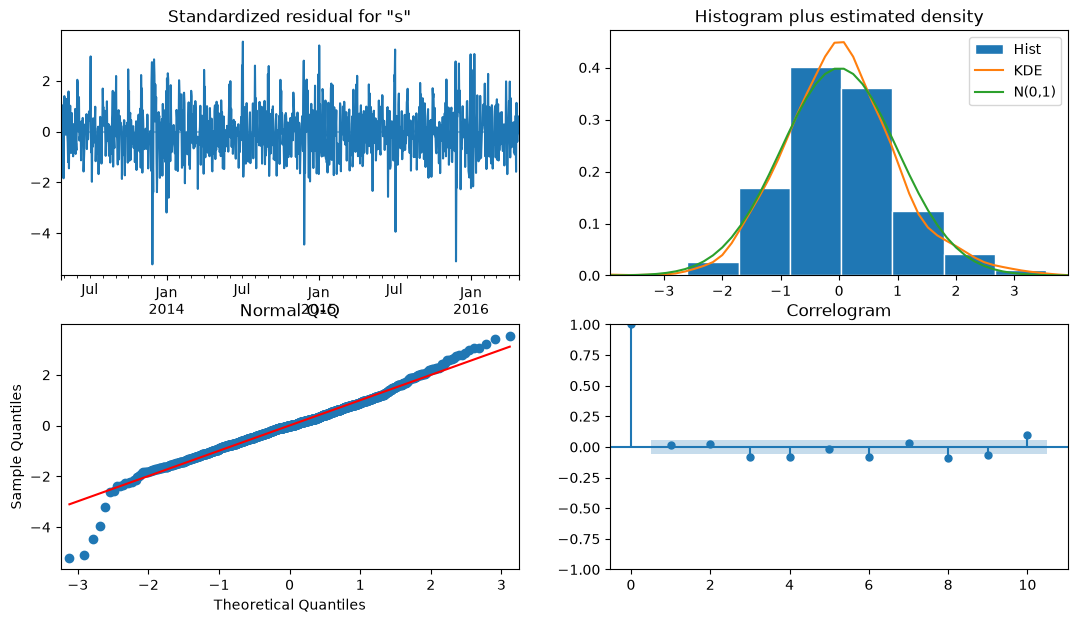

In [13]:
arima = ARIMA(ltrain, order=best[1]).fit()
print(arima.summary().tables[1])

fc = arima.get_forecast(H)
arima_pred = np.exp(fc.predicted_mean)
arima_pred.index = test.index
ci = np.exp(fc.conf_int())
ci.index = test.index

arima.plot_diagnostics(figsize=(13, 7))
plt.show()

Residuals look like random noise around zero and follow the reference line in the Q-Q plot. Small deviations at holiday spikes are expected.

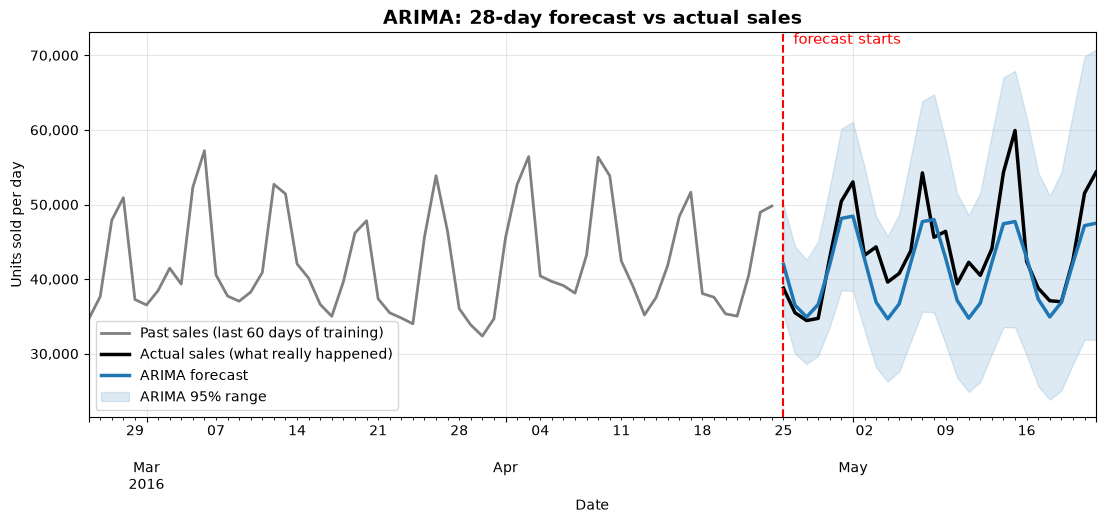

,actual,ARIMA forecast,lower 95%,upper 95%,error
2016-04-25,38793.0,41973.0,35258.0,49966.0,-3180.0
2016-04-26,35487.0,36495.0,30013.0,44375.0,-1008.0
2016-04-27,34445.0,34912.0,28626.0,42578.0,-467.0
2016-04-28,34732.0,36601.0,29732.0,45056.0,-1869.0
2016-04-29,42896.0,41941.0,33625.0,52313.0,955.0
2016-04-30,50429.0,48137.0,38509.0,60170.0,2292.0
2016-05-01,53032.0,48435.0,38422.0,61057.0,4597.0
2016-05-02,43181.0,42702.0,33143.0,55017.0,479.0
2016-05-03,44314.0,36920.0,28185.0,48362.0,7394.0
2016-05-04,39601.0,34665.0,26267.0,45749.0,4936.0


In [14]:
fig, ax = plt.subplots(figsize=(13, 5))
train.iloc[-60:].plot(ax=ax, label='Past sales (last 60 days of training)', color='gray', lw=2)
test.plot(ax=ax, label='Actual sales (what really happened)', color='black', lw=2.5)
arima_pred.plot(ax=ax, label='ARIMA forecast', color='#1f77b4', lw=2.5)
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color='#1f77b4', alpha=.15, label='ARIMA 95% range')
ax.axvline(test.index[0], color='red', ls='--', lw=1.5)
ax.text(test.index[0], ax.get_ylim()[1], '  forecast starts', color='red', va='top', fontsize=11)
ax.yaxis.set_major_formatter(thousands)
ax.set_title('ARIMA: 28-day forecast vs actual sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.grid(alpha=0.3)
ax.legend(loc='lower left')
plt.show()

out = pd.DataFrame({'actual': test, 'ARIMA forecast': arima_pred.round(0),
                    'lower 95%': ci.iloc[:, 0].round(0), 'upper 95%': ci.iloc[:, 1].round(0)})
out['error'] = (out['actual'] - out['ARIMA forecast']).round(0)
out.head(10)

**How to read this:** the black line is what really happened and the blue line is the ARIMA forecast. The shaded band is the range ARIMA expects sales to fall in 95% of the time.

### 3.3 Prophet
Prophet is given the calendar events as holidays. Seasonality is multiplicative because the weekly swing grows with sales.

Importing plotly failed. Interactive plots will not work.
21:41:02 - cmdstanpy - INFO - Chain [1] start processing
21:41:02 - cmdstanpy - INFO - Chain [1] done processing


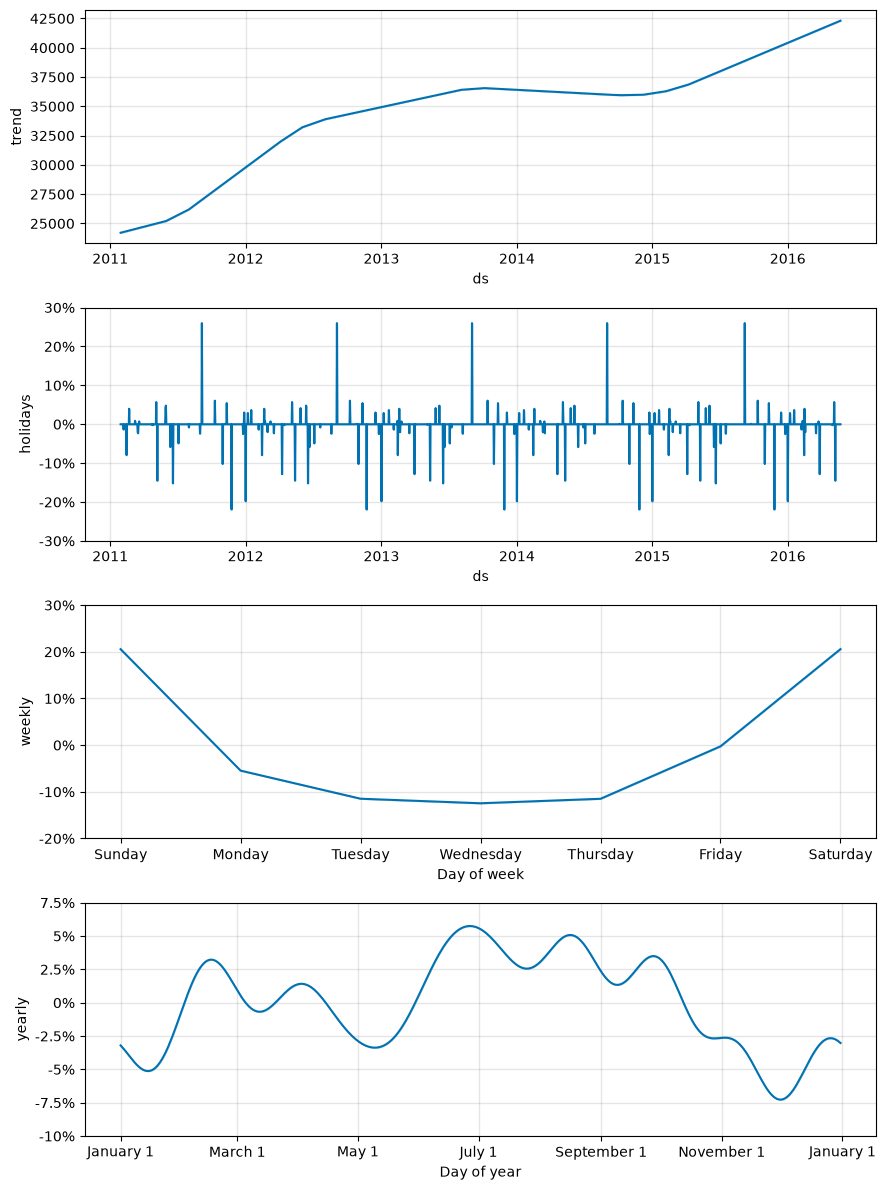

In [15]:
from prophet import Prophet

events = cal[['date', 'event_name_1']].dropna()
holidays = pd.DataFrame({'holiday': events.event_name_1, 'ds': events.date,
                         'lower_window': 0, 'upper_window': 0})

df_train = train.reset_index()
df_train.columns = ['ds', 'y']
prophet = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                  seasonality_mode='multiplicative', holidays=holidays)
prophet.fit(df_train)

pf = prophet.predict(prophet.make_future_dataframe(H, freq='D'))
prophet_pred = pf.set_index('ds')['yhat'].iloc[-H:]
prophet_pred.index = test.index

prophet.plot_components(pf)
plt.show()

The component plots show the learned trend, holiday effects, weekly shape and yearly shape.

### 3.4 Model comparison

In [16]:
results = pd.DataFrame([metrics(test, arima_pred, 'ARIMA'),
                        metrics(test, prophet_pred, 'Prophet')]).set_index('model')

display(results.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE (%)': '{:.2f}'})
        .background_gradient(cmap='RdYlGn_r', axis=0)
        .set_properties(**{'font-size': '13px', 'text-align': 'center'})
        .set_caption('Evaluation metrics (green = best, red = worst, lower is better)'))

winner = results['MAPE (%)'].idxmin()
print(f'Best model by MAPE: {winner} ({results.loc[winner, "MAPE (%)"]:.2f}% error)')

,MAE,RMSE,MAPE (%)
model,,,
ARIMA,"3,411","4,429",7.32
Prophet,"3,460","4,249",7.60


Best model by MAPE: ARIMA (7.32% error)


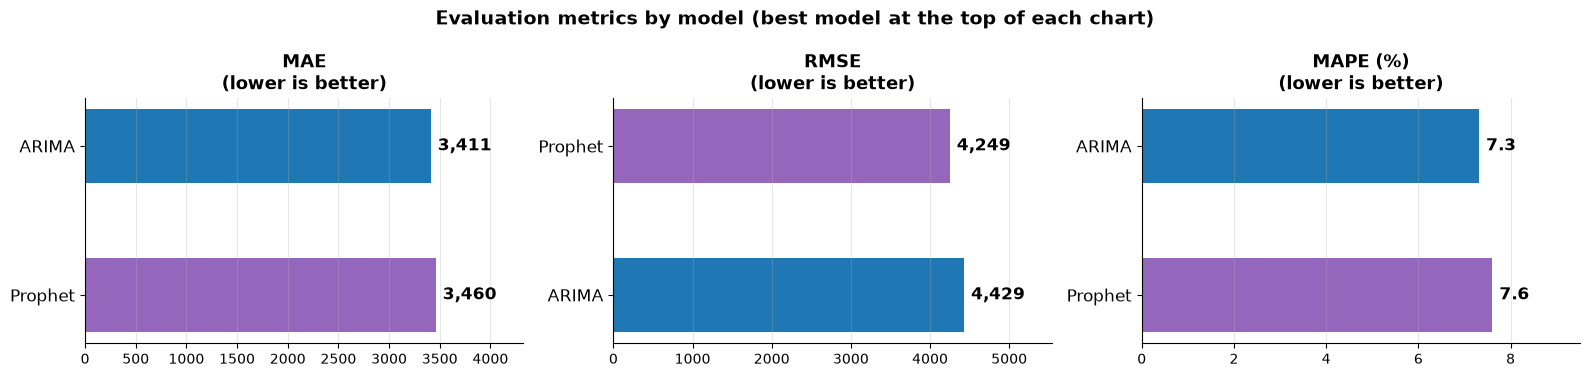

In [17]:
colors = {'ARIMA': '#1f77b4', 'Prophet': '#9467bd'}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ['MAE', 'RMSE', 'MAPE (%)']):
    vals = results[col].sort_values(ascending=False)
    bars = ax.barh(vals.index, vals.values, color=[colors[m] for m in vals.index], height=0.5)
    for bar, v in zip(bars, vals.values):
        txt = f'{v:.1f}' if col == 'MAPE (%)' else f'{v:,.0f}'
        ax.text(v + vals.max() * 0.02, bar.get_y() + bar.get_height() / 2, txt, va='center', fontsize=12, fontweight='bold')
    ax.set_title(col + '\n(lower is better)', fontsize=13, fontweight='bold')
    ax.set_xlim(0, vals.max() * 1.25)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.suptitle('Evaluation metrics by model (best model at the top of each chart)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

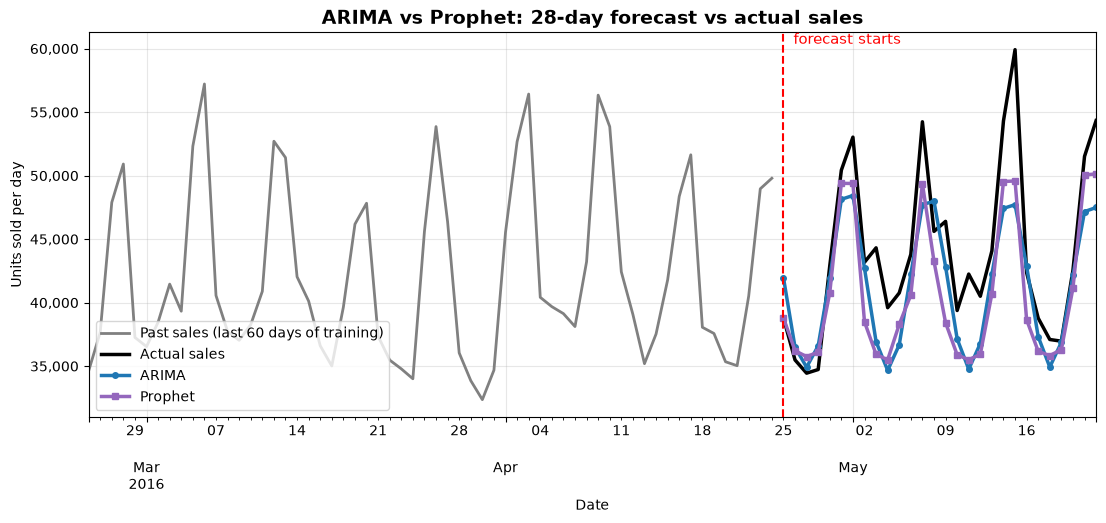

In [18]:
fig, ax = plt.subplots(figsize=(13, 5))
train.iloc[-60:].plot(ax=ax, label='Past sales (last 60 days of training)', color='gray', lw=2)
test.plot(ax=ax, label='Actual sales', color='black', lw=2.5)
arima_pred.plot(ax=ax, label='ARIMA', color='#1f77b4', lw=2.5, marker='o', ms=4)
prophet_pred.plot(ax=ax, label='Prophet', color='#9467bd', lw=2.5, marker='s', ms=4)
ax.axvline(test.index[0], color='red', ls='--', lw=1.5)
ax.text(test.index[0], ax.get_ylim()[1], '  forecast starts', color='red', va='top', fontsize=11)
ax.yaxis.set_major_formatter(thousands)
ax.set_title('ARIMA vs Prophet: 28-day forecast vs actual sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.grid(alpha=0.3)
ax.legend(loc='lower left')
plt.show()

**How to read this:** the closer a coloured line is to the black line, the better the model. Both models follow the weekly rhythm but miss the highest weekend peaks.